<a href="https://colab.research.google.com/github/jisjeeson/ICT_ASSESSMENTS/blob/main/Transfer_Learning_CIFAR10_JIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import Libraries

In [2]:

# Basic libraries
import os
import copy
import time
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import EfficientNet_B0_Weights

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Progress bar
from tqdm.notebook import tqdm

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Check GPU availability

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not available. Please enable GPU runtime.")


PyTorch version: 2.14.1+cu130
Selected device: cuda
GPU: Tesla T4
CUDA version: 13.0


# Dataset and Image Preprocessing


In [4]:

# Dataset location
dataset_path = "./data"

# ImageNet normalization values
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Transformations for training images
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Transformations for validation and test images
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Image transformations defined successfully!")


Image transformations defined successfully!


In [5]:

# Training dataset
train_dataset = datasets.CIFAR10(
    root=dataset_path,
    train=True,
    download=True,
    transform=train_transform
)

# Validation dataset
val_dataset = datasets.CIFAR10(
    root=dataset_path,
    train=True,
    download=True,
    transform=test_transform
)

# Test dataset
test_dataset = datasets.CIFAR10(
    root=dataset_path,
    train=False,
    download=True,
    transform=test_transform
)

# Class names
class_names = train_dataset.classes

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Validation source images:", len(val_dataset))
print("Test images:", len(test_dataset))


100%|██████████| 170M/170M [18:44<00:00, 152kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Validation source images: 50000
Test images: 10000


In [6]:

# Create training and validation indices
indices = np.arange(len(train_dataset))
labels = np.array(train_dataset.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.1,
    random_state=42,
    stratify=labels
)

# Create separate datasets
train_data = Subset(train_dataset, train_indices)
val_data = Subset(val_dataset, val_indices)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Testing samples:", len(test_dataset))


Training samples: 45000
Validation samples: 5000
Testing samples: 10000


In [7]:

batch_size = 128

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


DataLoaders created successfully!
Training batches: 352
Validation batches: 40
Testing batches: 79


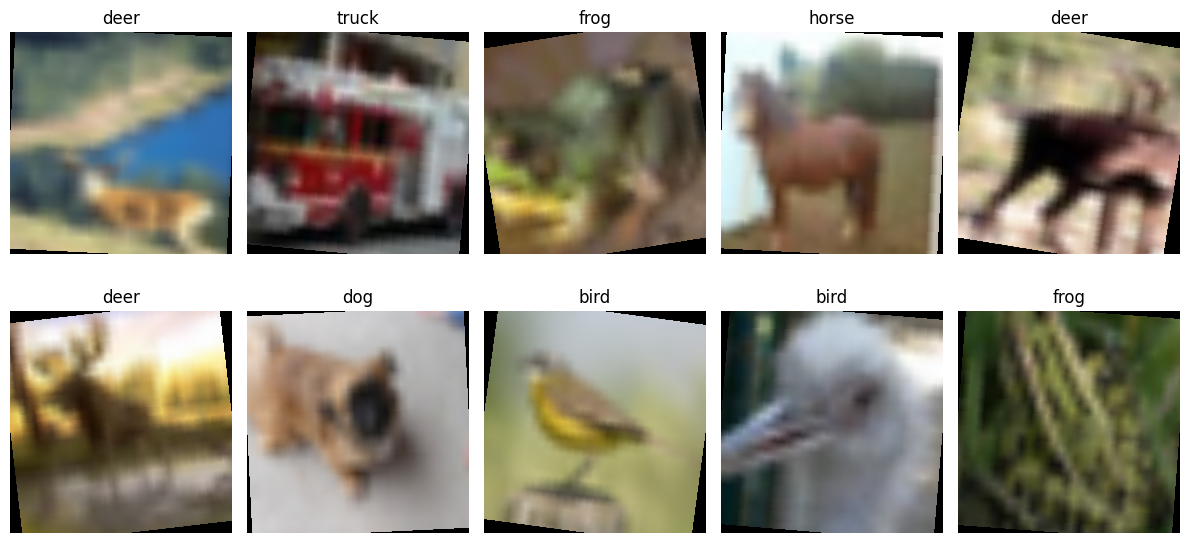

In [8]:

# Display sample images from the training dataset

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))

for i in range(10):

    # Convert image back to original colour scale
    image = images[i].permute(1, 2, 0).numpy()
    image = image * np.array(std) + np.array(mean)
    image = np.clip(image, 0, 1)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

# Load pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT

backbone = models.efficientnet_b0(weights=weights)

# Freeze pretrained feature extraction layers
for param in backbone.features.parameters():
    param.requires_grad = False

# Get number of input features
num_features = backbone.classifier[1].in_features

print("EfficientNet-B0 loaded successfully!")
print("Number of input features:", num_features)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 60.2MB/s]


EfficientNet-B0 loaded successfully!
Number of input features: 1280


In [10]:

# Remove the original ImageNet classifier
backbone.classifier = nn.Identity()

# Build the new classification model
model = nn.Sequential(
    backbone,
    nn.Linear(num_features, 512),
    nn.BatchNorm1d(512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 10)
)

# He initialization for hidden layer
nn.init.kaiming_normal_(
    model[1].weight,
    nonlinearity="relu"
)
nn.init.zeros_(model[1].bias)

# Xavier initialization for output layer
nn.init.xavier_uniform_(model[5].weight)
nn.init.zeros_(model[5].bias)

# Move model to GPU
model = model.to(
    device,
    memory_format=torch.channels_last
)

print("Model built successfully!")
print("Model device:", next(model.parameters()).device)
print(model)


Model built successfully!
Model device: cuda:0
Sequential(
  (0): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
       

In [11]:

# Loss function
criterion = nn.CrossEntropyLoss()

# AdamW optimizer
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=1e-4
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Scheduler:", scheduler)


Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7cc088712cf0>


In [12]:
# Enable mixed precision training
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# Enable cuDNN benchmarking
torch.backends.cudnn.benchmark = True

print("Mixed precision enabled:", device.type == "cuda")

Mixed precision enabled: True


In [13]:

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, leave=False):

        images = images.to(
            device,
            non_blocking=True,
            memory_format=torch.channels_last
        )

        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision
        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):

            outputs = model(images)
            loss = criterion(outputs, labels)

        # Backpropagation
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

    epoch_loss = total_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


In [14]:

def validate_model(model, loader, criterion):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True,
                memory_format=torch.channels_last
            )

            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    epoch_loss = total_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions are ready!")


Training and validation functions are ready!


In [15]:

def train_model(model, train_loader, val_loader, criterion,
                optimizer, scheduler, phase_name,
                max_epochs=10, min_epochs=10, patience=5):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    wait = 0

    for epoch in range(max_epochs):

        start_time = time.time()

        # Training
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer
        )

        # Validation
        val_loss, val_acc = validate_model(
            model, val_loader, criterion
        )

        # Update learning rate
        scheduler.step(val_loss)

        # Store training history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # Save the best model
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

            torch.save(
                best_weights,
                f"best_{phase_name}.pth"
            )

            wait = 0

        else:
            wait += 1

        print(
            f"Epoch {epoch + 1}/{max_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_acc:.2f}% | "
            f"Validation Loss: {val_loss:.4f} | "
            f"Validation Accuracy: {val_acc:.2f}% | "
            f"Time: {time.time() - start_time:.1f}s"
        )

        # Early stopping
        if epoch + 1 >= min_epochs and wait >= patience:
            print("Early stopping triggered!")
            break

    # Restore best weights
    model.load_state_dict(best_weights)

    return model, history


print("Main training function is ready!")


Main training function is ready!


In [16]:

model, history_feature = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    phase_name="feature_extraction",
    max_epochs=20,
    min_epochs=20,
    patience=5
)

print("Feature extraction training completed!")


  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 1/20 | Train Loss: 1.0572 | Train Accuracy: 64.13% | Validation Loss: 0.6068 | Validation Accuracy: 79.46% | Time: 119.5s


  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 2/20 | Train Loss: 0.8346 | Train Accuracy: 70.86% | Validation Loss: 0.5970 | Validation Accuracy: 80.12% | Time: 107.7s


  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 3/20 | Train Loss: 0.7892 | Train Accuracy: 72.34% | Validation Loss: 0.5669 | Validation Accuracy: 80.46% | Time: 108.1s


... (30 outputs left out)

  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 19/20 | Train Loss: 0.6456 | Train Accuracy: 77.55% | Validation Loss: 0.4890 | Validation Accuracy: 83.26% | Time: 109.7s


  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 20/20 | Train Loss: 0.6469 | Train Accuracy: 77.40% | Validation Loss: 0.4834 | Validation Accuracy: 83.94% | Time: 108.4s
Feature extraction training completed!


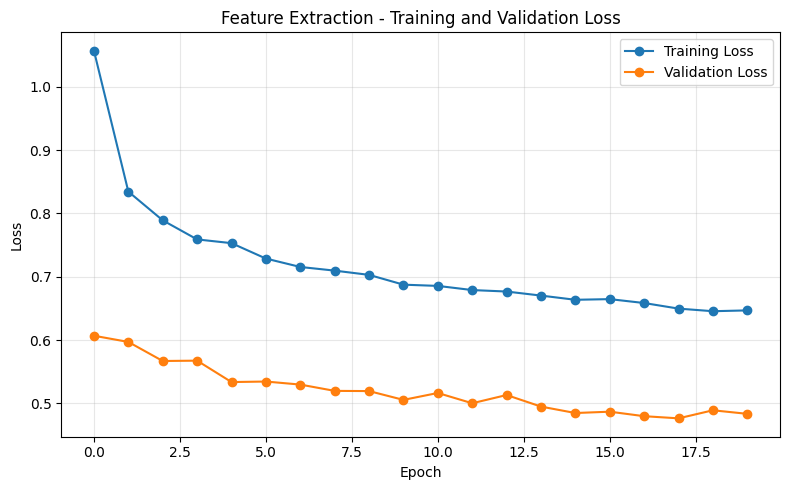

In [17]:

plt.figure(figsize=(8, 5))

plt.plot(
    history_feature["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history_feature["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Feature Extraction - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


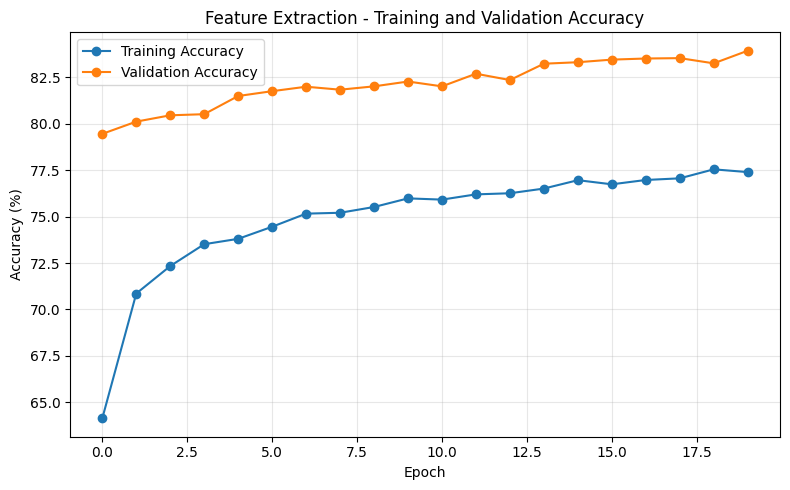

In [18]:

plt.figure(figsize=(8, 5))

plt.plot(
    history_feature["train_acc"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history_feature["val_acc"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Feature Extraction - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

torch.save(
    model.state_dict(),
    "efficientnet_feature_extraction.pth"
)

print("Feature extraction model saved successfully!")


Feature extraction model saved successfully!


. Interpretation of feature extraction results
1. Training vs Validation Loss
- Both losses decrease over the 20 epochs.
- Validation loss finishes around 0.48.
- No major signs of overfitting.
2. Training vs Validation Accuracy
- Training accuracy reaches approximately 77.4%.
- Validation accuracy reaches approximately 83.94%.
- Validation accuracy remains consistently higher than training accuracy

In [20]:

# Unfreeze the last two feature blocks
for param in model[0].features[7:].parameters():
    param.requires_grad = True

# Check trainable and frozen parameters
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

frozen_params = sum(
    p.numel() for p in model.parameters() if not p.requires_grad
)

print("Fine-tuning layers unfrozen successfully!")
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", frozen_params)


Fine-tuning layers unfrozen successfully!
Trainable parameters: 1791418
Frozen parameters: 2878156


In [21]:

# Configure optimizer for fine-tuning
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5,
    weight_decay=1e-4
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("Fine-tuning optimizer configured!")
print("Learning rate:", optimizer.param_groups[0]["lr"])


Fine-tuning optimizer configured!
Learning rate: 1e-05


In [22]:

model, history_finetune = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    phase_name="fine_tuning",
    max_epochs=10,
    min_epochs=10,
    patience=5
)

print("Fine-tuning completed successfully!")


  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 1/10 | Train Loss: 0.6285 | Train Accuracy: 77.96% | Validation Loss: 0.4546 | Validation Accuracy: 84.26% | Time: 115.3s


  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 2/10 | Train Loss: 0.6065 | Train Accuracy: 78.87% | Validation Loss: 0.4507 | Validation Accuracy: 84.64% | Time: 109.8s


  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 3/10 | Train Loss: 0.5860 | Train Accuracy: 79.46% | Validation Loss: 0.4371 | Validation Accuracy: 84.84% | Time: 110.5s


... (10 outputs left out)

  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 9/10 | Train Loss: 0.5201 | Train Accuracy: 81.89% | Validation Loss: 0.4071 | Validation Accuracy: 85.84% | Time: 109.7s


  0%|          | 0/352 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.5105 | Train Accuracy: 82.10% | Validation Loss: 0.3875 | Validation Accuracy: 86.78% | Time: 108.8s
Fine-tuning completed successfully!


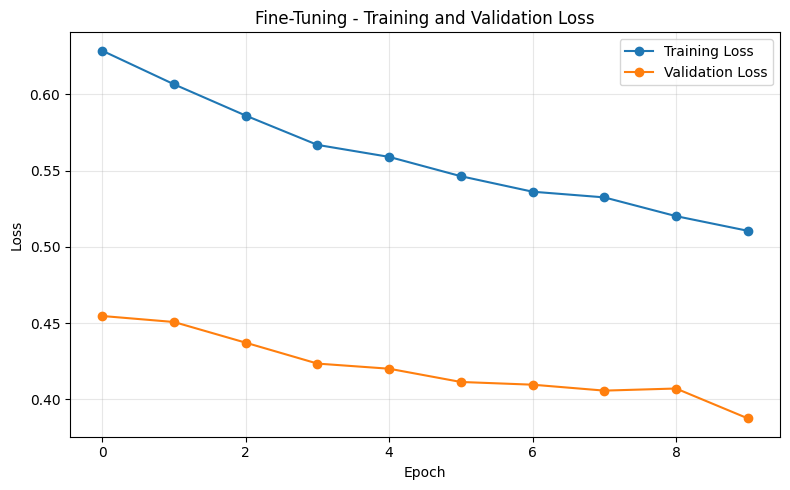

In [23]:

plt.figure(figsize=(8, 5))

plt.plot(history_finetune["train_loss"], label="Training Loss", marker="o")
plt.plot(history_finetune["val_loss"], label="Validation Loss", marker="o")

plt.title("Fine-Tuning - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

print("PERFORMANCE COMPARISON")
print("-" * 50)

feature_acc = max(history_feature["val_acc"])
finetune_acc = max(history_finetune["val_acc"])

print(f"Feature Extraction Accuracy: {feature_acc:.2f}%")
print(f"Fine-Tuning Accuracy:        {finetune_acc:.2f}%")

print(f"Improvement:                 {finetune_acc - feature_acc:.2f}%")


PERFORMANCE COMPARISON
--------------------------------------------------
Feature Extraction Accuracy: 83.94%
Fine-Tuning Accuracy:        86.78%
Improvement:                 2.84%


In [25]:

torch.save(
    model.state_dict(),
    "efficientnet_finetuned.pth"
)

print("Fine-tuned model saved successfully!")


Fine-tuned model saved successfully!


In [26]:

# Evaluate the fine-tuned model on the test dataset

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in tqdm(test_loader):

        images = images.to(
            device,
            non_blocking=True,
            memory_format=torch.channels_last
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Test evaluation completed!")
print("Total test samples:", len(all_labels))


  0%|          | 0/79 [00:00<?, ?it/s]

Test evaluation completed!
Total test samples: 10000


In [27]:

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Test Accuracy: 85.51%


In [28]:

report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
)

print("Classification Report")
print("-" * 60)
print(report)


Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

    airplane       0.85      0.89      0.87      1000
  automobile       0.93      0.92      0.92      1000
        bird       0.87      0.82      0.84      1000
         cat       0.79      0.63      0.70      1000
        deer       0.85      0.82      0.83      1000
         dog       0.82      0.80      0.81      1000
        frog       0.84      0.93      0.88      1000
       horse       0.85      0.90      0.88      1000
        ship       0.90      0.89      0.89      1000
       truck       0.84      0.94      0.89      1000

    accuracy                           0.86     10000
   macro avg       0.85      0.86      0.85     10000
weighted avg       0.85      0.86      0.85     10000



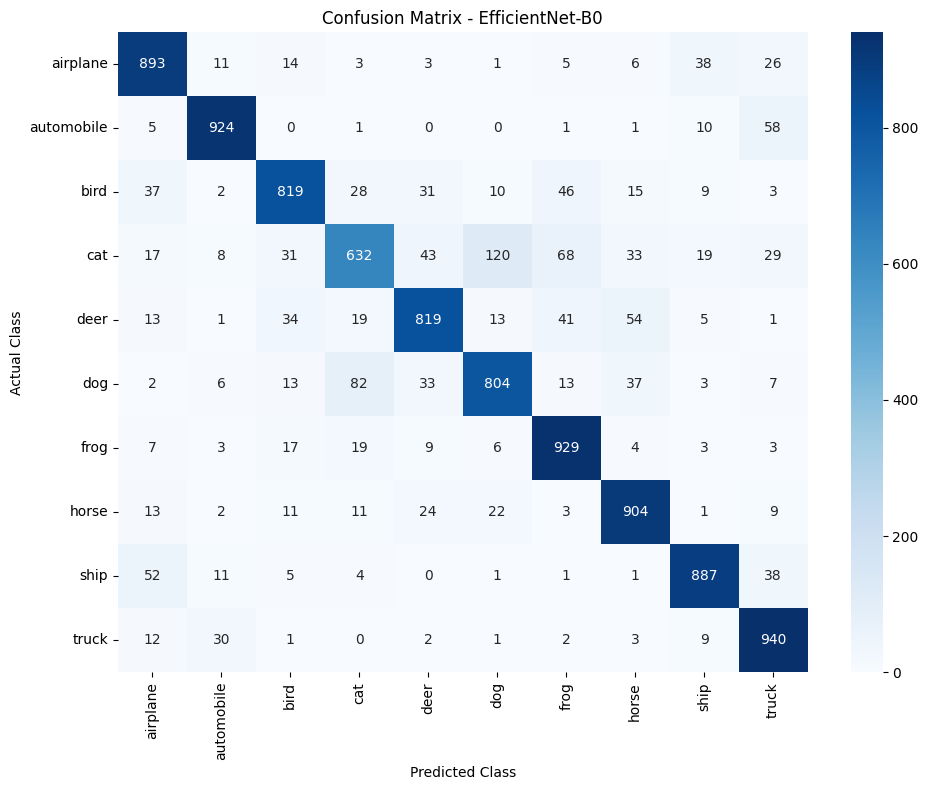

In [29]:

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - EfficientNet-B0")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


In [30]:

per_class_accuracy = cm.diagonal() / cm.sum(axis=1) * 100

for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: {per_class_accuracy[i]:.2f}%"
    )

# Identify the hardest classes
hardest_indices = np.argsort(per_class_accuracy)[:3]

print("\nThree hardest classes:")

for i in hardest_indices:
    print(
        f"{class_names[i]}: {per_class_accuracy[i]:.2f}%"
    )


airplane: 89.30%
automobile: 92.40%
bird: 81.90%
cat: 63.20%
deer: 81.90%
dog: 80.40%
frog: 92.90%
horse: 90.40%
ship: 88.70%
truck: 94.00%

Three hardest classes:
cat: 63.20%
dog: 80.40%
deer: 81.90%


In [31]:

# Save final fine-tuned model
torch.save(
    model.state_dict(),
    "efficientnet_final_model.pth"
)

# Save classification report
report_dict = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    output_dict=True
)

import pandas as pd

report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv("classification_report.csv")

# Save confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv("confusion_matrix.csv")

print("Final model and evaluation results saved!")


Final model and evaluation results saved!


Conclusion
- Successfully developed an image classification model using transfer learning with pretrained EfficientNet-B0.
- Used CIFAR-10 dataset with 10 classes for model training and evaluation.
- Applied data augmentation and ImageNet normalization to improve model generalization.
- Implemented Batch Normalization, Dropout and weight decay to reduce overfitting.
- Completed 20 epochs of feature extraction followed by 10 epochs of fine-tuning.
- Fine-tuning improved validation accuracy from 83.94% to 86.78%.
- Achieved 85.51% accuracy on the test dataset.
- Evaluated performance using a confusion matrix, classification report and per-class accuracy.
- Identified cats as the most challenging class for classification.
Overall, the project demonstrates how transfer learning can be used to build an effective image classification model with good generalization on CIFAR-10.